# — Task 3: Data Visualization

This notebook transforms e-commerce data into charts and graphs, uses Matplotlib and Seaborn, explains insights, and builds a short data story for decision-making.

**Dataset:** `Ecommerce_Dataset_3000.csv` (3,000-row sample; results apply to this sample only).


## Questions for visualization
1. Which product categories have the most records?
2. What is the order-status distribution and cancellation share?
3. What does the order-amount distribution look like, and are there possible outliers?
4. Which fulfilment and shipping service levels are most common?
5. Which shipping states have the most records?
6. How does average order amount vary by category?
7. How do amounts compare between Expedited and Standard shipping?


## Load data and libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
    SEABORN_AVAILABLE = True
except ImportError:
    SEABORN_AVAILABLE = False

df = pd.read_csv(Path("Ecommerce_Dataset_3000.csv"), low_memory=False)
df.columns = df.columns.str.strip()
for col in ["Amount", "Qty"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (3000, 24)


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


## 1. Product category distribution

,records
Category,
Set,1228
kurta,1184
Western Dress,284
Top,257
Blouse,19
Ethnic Dress,17
Bottom,7
Saree,4


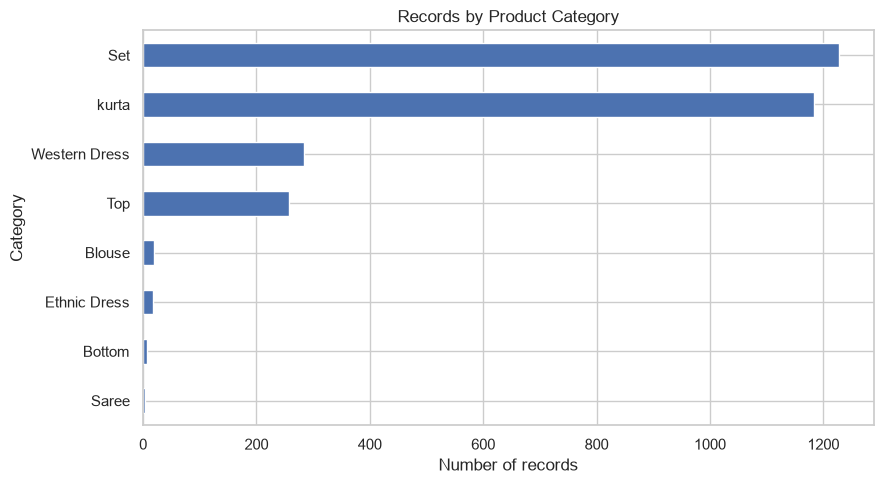

Insight: most frequent category is Set (1,228 records).


In [2]:
counts = df["Category"].fillna("Missing").value_counts()
display(counts.to_frame("records"))
ax = counts.sort_values().plot(kind="barh", figsize=(9,5), title="Records by Product Category")
ax.set_xlabel("Number of records"); ax.set_ylabel("Category")
plt.tight_layout(); plt.show()
print(f"Insight: most frequent category is {counts.index[0]} ({counts.iloc[0]:,} records).")


## 2. Order status distribution

,records
Status,
Shipped,2002
Shipped - Delivered to Buyer,528
Cancelled,438
Shipped - Returned to Seller,31
Shipped - Rejected by Buyer,1


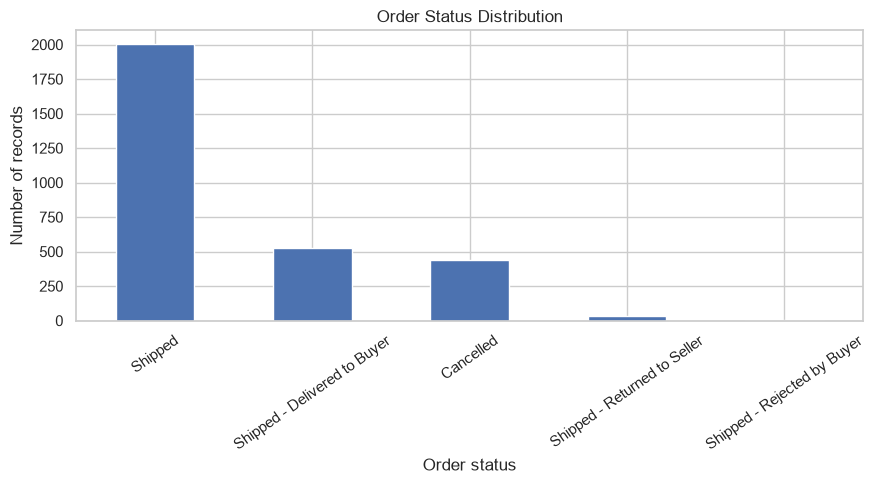

Insight: 438 records (14.6%) have a status containing 'cancel'.


In [3]:
counts = df["Status"].fillna("Missing").value_counts()
display(counts.to_frame("records"))
ax = counts.plot(kind="bar", figsize=(9,5), title="Order Status Distribution")
ax.set_xlabel("Order status"); ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()
cancelled = df["Status"].fillna("").astype(str).str.lower().str.contains("cancel")
print(f"Insight: {int(cancelled.sum())} records ({cancelled.mean()*100:.1f}%) have a status containing 'cancel'.")


## 3. Order amount distribution and possible outliers

,Amount summary
count,2780.000000
mean,624.411169
std,274.855094
min,0.000000
25%,432.000000
50%,574.000000
75%,771.000000
max,2224.000000


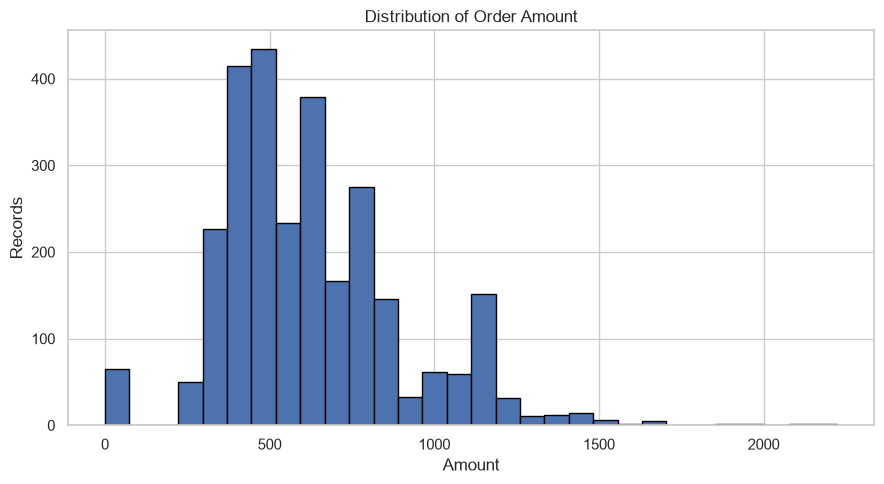

C:\Users\ASUS\AppData\Local\Temp\ipykernel_18092\2959863154.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.figure(figsize=(9,3)); plt.boxplot(amount, vert=False)


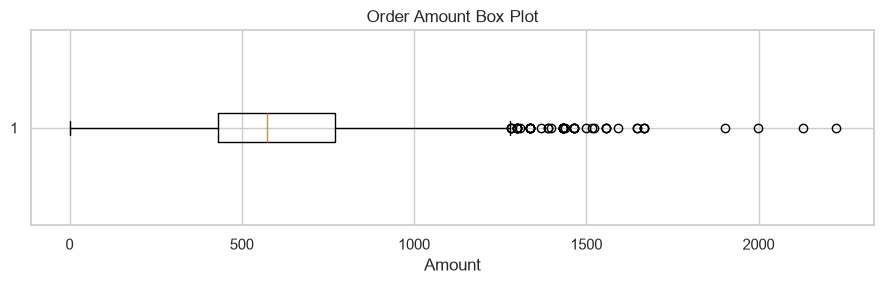

Mean=624.41; median=574.00
Potential IQR outliers=52; investigate rather than automatically deleting.


In [4]:
amount = df["Amount"].dropna()
display(amount.describe().to_frame("Amount summary"))
plt.figure(figsize=(9,5)); plt.hist(amount, bins=30, edgecolor="black")
plt.title("Distribution of Order Amount"); plt.xlabel("Amount"); plt.ylabel("Records")
plt.tight_layout(); plt.show()
plt.figure(figsize=(9,3)); plt.boxplot(amount, vert=False)
plt.title("Order Amount Box Plot"); plt.xlabel("Amount")
plt.tight_layout(); plt.show()
q1,q3 = amount.quantile([.25,.75]); iqr=q3-q1
lower,upper=q1-1.5*iqr,q3+1.5*iqr
outliers=int(((amount<lower)|(amount>upper)).sum())
print(f"Mean={amount.mean():.2f}; median={amount.median():.2f}")
print(f"Potential IQR outliers={outliers}; investigate rather than automatically deleting.")


## 4. Fulfilment and shipping service level

,records
Fulfilment,
Amazon,2307
Merchant,693


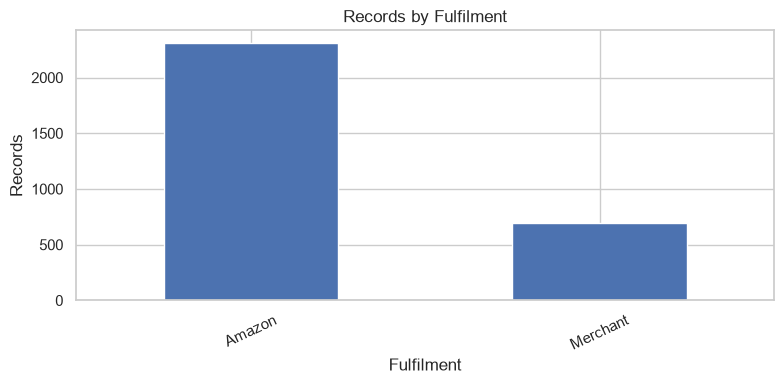

Insight: most common Fulfilment is Amazon (2,307 records).


,records
ship-service-level,
Expedited,2271
Standard,729


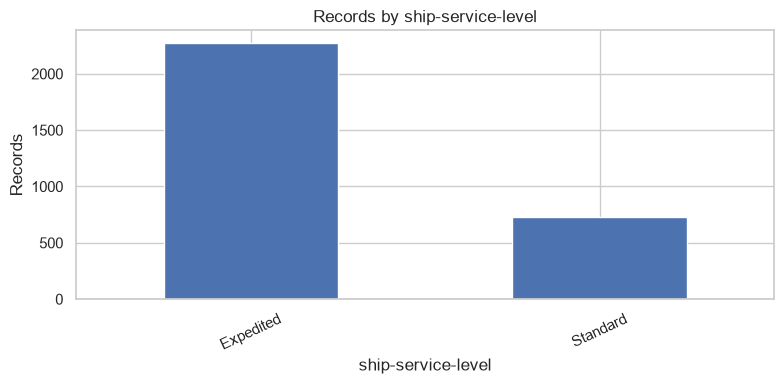

Insight: most common ship-service-level is Expedited (2,271 records).


In [5]:
for col in ["Fulfilment", "ship-service-level"]:
    counts = df[col].fillna("Missing").value_counts()
    display(counts.to_frame("records"))
    ax=counts.plot(kind="bar", figsize=(8,4), title=f"Records by {col}")
    ax.set_xlabel(col); ax.set_ylabel("Records"); ax.tick_params(axis="x", rotation=25)
    plt.tight_layout(); plt.show()
    print(f"Insight: most common {col} is {counts.index[0]} ({counts.iloc[0]:,} records).")


## 5. Top shipping states

,records
ship-state,
MAHARASHTRA,517
KARNATAKA,380
TELANGANA,281
TAMIL NADU,252
UTTAR PRADESH,239
WEST BENGAL,155
DELHI,132
Gujarat,132
KERALA,121


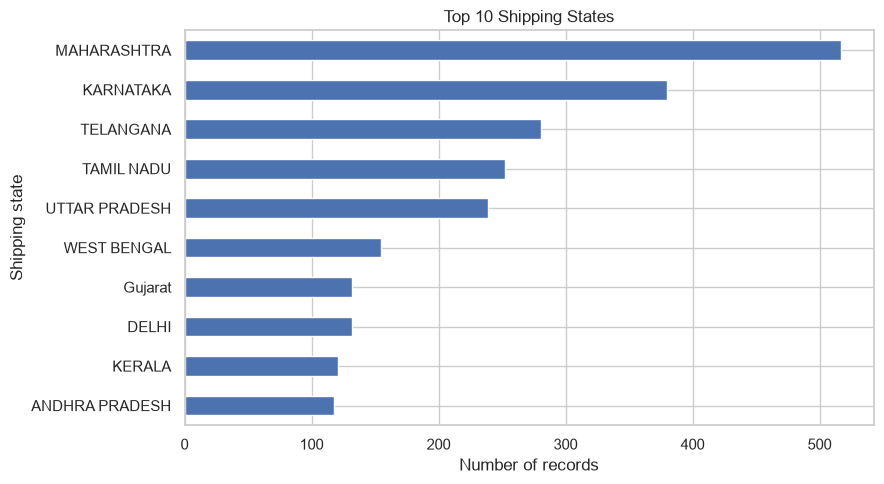

Insight: MAHARASHTRA is the most frequent state in this sample.


In [6]:
counts=df["ship-state"].fillna("Missing").value_counts().head(10)
display(counts.to_frame("records"))
ax=counts.sort_values().plot(kind="barh", figsize=(9,5), title="Top 10 Shipping States")
ax.set_xlabel("Number of records"); ax.set_ylabel("Shipping state")
plt.tight_layout(); plt.show()
print(f"Insight: {counts.index[0]} is the most frequent state in this sample.")


## 6. Average order amount by category

,records,mean_amount,median_amount
Category,,,
Set,1136,815.856673,788.0
Saree,4,811.750000,819.0
Ethnic Dress,17,809.588235,845.0
Western Dress,259,732.983127,744.0
Top,245,490.339755,493.0
Blouse,18,433.851667,460.0
kurta,1094,431.295859,406.0
Bottom,7,345.285714,360.0


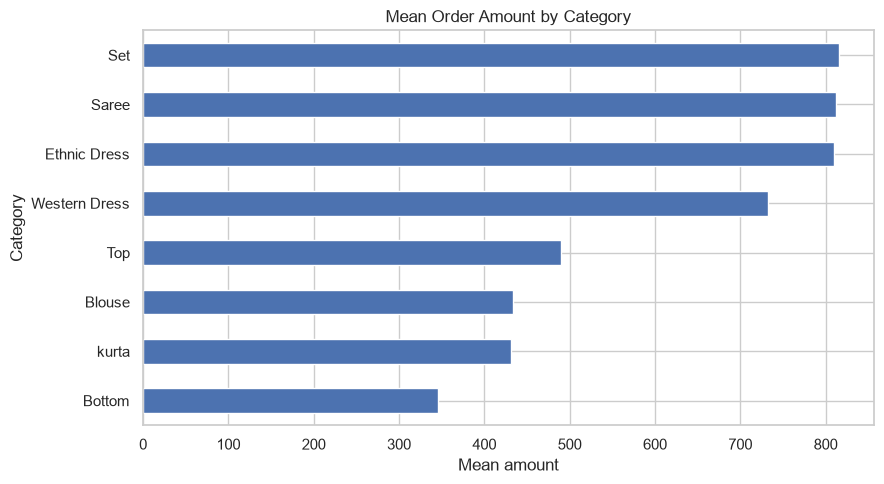

Insight: compare mean and median together because extreme orders can influence the mean.


In [9]:
summary=(df.dropna(subset=["Amount"]).groupby("Category")["Amount"]
         .agg(records="count", mean_amount="mean", median_amount="median")
         .sort_values("mean_amount", ascending=False))
display(summary)
ax=summary["mean_amount"].sort_values().plot(kind="barh", figsize=(9,5), title="Mean Order Amount by Category")
ax.set_xlabel("Mean amount"); ax.set_ylabel("Category")
plt.tight_layout(); plt.show()
print("Insight: compare mean and median together because extreme orders can influence the mean.")


## 7. Order amount by shipping service level

,count,mean,median,std
ship-service-level,,,,
Expedited,2088,641.311782,597.0,262.333628
Standard,692,573.416257,533.5,304.142671


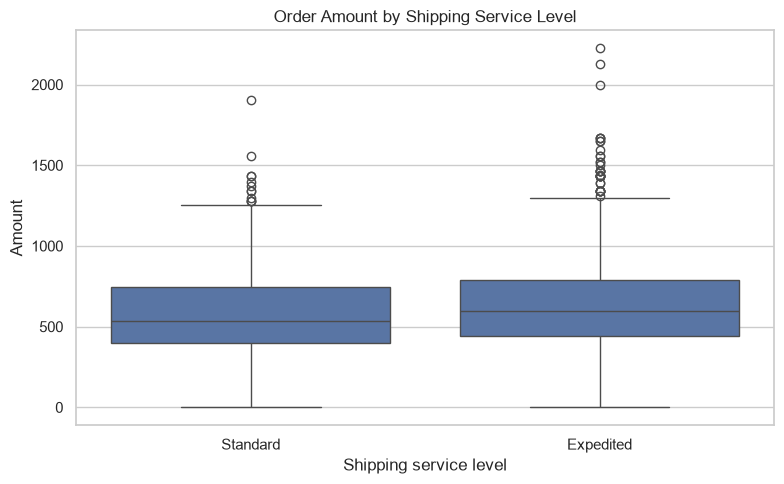

Welch t-test: statistic=5.2597, p-value=0.000000
At 5% significance: evidence of different means


In [8]:
valid=df.dropna(subset=["Amount","ship-service-level"])
display(valid.groupby("ship-service-level")["Amount"].agg(["count","mean","median","std"]))
fig,ax=plt.subplots(figsize=(8,5))
if SEABORN_AVAILABLE:
    sns.boxplot(data=valid, x="ship-service-level", y="Amount", ax=ax)
else:
    groups=[g["Amount"].values for _,g in valid.groupby("ship-service-level")]
    labels=[name for name,_ in valid.groupby("ship-service-level")]
    ax.boxplot(groups, labels=labels)
ax.set_title("Order Amount by Shipping Service Level")
ax.set_xlabel("Shipping service level"); ax.set_ylabel("Amount")
plt.tight_layout(); plt.show()
try:
    from scipy.stats import ttest_ind
    a=valid.loc[valid["ship-service-level"].eq("Expedited"),"Amount"]
    b=valid.loc[valid["ship-service-level"].eq("Standard"),"Amount"]
    if len(a)>1 and len(b)>1:
        t,p=ttest_ind(a,b,equal_var=False)
        print(f"Welch t-test: statistic={t:.4f}, p-value={p:.6f}")
        print("At 5% significance:", "evidence of different means" if p<.05 else "no statistically significant difference detected")
except ImportError:
    print("Install scipy to run the optional Welch t-test.")


## Conclusion and data story

These visuals summarize product-category frequency, order outcomes, order-value distribution, fulfilment/shipping patterns, geography, and category-level order value. The insights can support inventory review, cancellation monitoring, and operational planning.

**Important limitations:** this is a 3,000-row sample; missing amounts are excluded from amount charts; possible outliers are flags for review rather than confirmed errors; and visual associations do not prove causation. Validate findings against the full dataset before making business decisions.
